# Bonus Tasks + Baseline Training
## Computer Vision Final Project – Fruit Ripeness Classification

This notebook:
1. Trains the baseline MobileNetV3‑Small (without SE) for comparison.
2. Loads the pre‑trained SE model (from your main project).
3. Produces the architectural comparison table.
4. Runs Grad‑CAM on the SE model.
5. Performs model quantization and generates a trade‑off table.

## Step 1: Setup and imports

In [1]:
!pip install grad-cam -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 58.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [10]:
# Standard library
import os
import time
import random
import copy
import sys

# Numerical & plotting
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision.transforms as transforms
import torchvision.models as models

# Image loading
from PIL import Image

# Scikit-learn (if needed)
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.preprocessing import label_binarize

# Grad-CAM
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

# Quantization
import torch.quantization as quant

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Device selection
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch version : {torch.__version__}")
print(f"Using device    : {DEVICE}")
if DEVICE.type == "cuda":
    print(f" GPU             : {torch.cuda.get_device_name(0)}")

PyTorch version : 2.11.0+cu128
Using device    : cuda
 GPU             : Tesla T4


## Step 2: Connect to Google Drive

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# EXTRACT DATA
import os
import zipfile
!rm -rf /content/fruit_ripeness_dataset
!unzip -q /content/drive/MyDrive/fruit_ripeness_dataset.zip -d /content/

## Step 3: Define paths & dataset class

In [11]:
# PATHS
DATA_ROOT = "/content/fruit_ripeness_dataset/dataset"
TRAIN_DIR = os.path.join(DATA_ROOT, "train")
TEST_DIR  = os.path.join(DATA_ROOT, "test")

# Where models will be saved
SAVE_DIR = "/content/drive/MyDrive/cv_project_v2/saved_models"
os.makedirs(SAVE_DIR, exist_ok=True)

# SE model checkpoint
SE_CHECKPOINT = os.path.join(SAVE_DIR, "best_model_v2.pth")

# Baseline checkpoint will be saved here
BASELINE_CHECKPOINT = os.path.join(SAVE_DIR, "baseline_best.pth")

# Hyperparameters (same as your v2 training)
IMG_SIZE = 224
BATCH_SIZE = 64
NUM_EPOCHS_BASELINE = 30
LR = 1e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 4
VAL_SPLIT = 0.15

# Verify directories exist
print("Directory Check ....")
for name, path in [("Train", TRAIN_DIR), ("Test", TEST_DIR), ("Save", SAVE_DIR)]:
    status = "Found" if os.path.isdir(path) else "NOT FOUND - check path"
    print(f"  {name:<6}: {path}  →  {status}")


# Dataset class
class CustomFruitDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.samples = []
        all_entries = os.listdir(root_dir)
        self.classes = sorted([
            entry for entry in all_entries
            if os.path.isdir(os.path.join(root_dir, entry))
            and not entry.startswith('.')
        ])
        self.class_to_idx = {cls: i for i, cls in enumerate(self.classes)}
        for class_name in self.classes:
            class_folder = os.path.join(root_dir, class_name)
            for fname in sorted(os.listdir(class_folder)):
                if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
                    full_path = os.path.join(class_folder, fname)
                    label = self.class_to_idx[class_name]
                    self.samples.append((full_path, label))
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

Directory Check ....
  Train : /content/fruit_ripeness_dataset/dataset/train  →  Found
  Test  : /content/fruit_ripeness_dataset/dataset/test  →  Found
  Save  : /content/drive/MyDrive/cv_project_v2/saved_models  →  Found


## Step 4: Transforms Pipeline

In [12]:
# Training transform (with augmentation)
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.1),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.05),
    transforms.RandomGrayscale(p=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Base transform (no augmentation)
base_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Inverse normalization for visualization
inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)

## Step 5: Build Datasets & Loaders

In [13]:
# Build Datasets & Loaders
full_train_dataset = CustomFruitDataset(TRAIN_DIR, transform=train_transform)
total_train = len(full_train_dataset)
val_count = int(total_train * VAL_SPLIT)
train_count = total_train - val_count
generator = torch.Generator().manual_seed(SEED)
train_subset, val_subset = random_split(full_train_dataset, [train_count, val_count], generator=generator)

# Validation dataset with base_transform
val_dataset_clean = CustomFruitDataset(TRAIN_DIR, transform=base_transform)
class SubsetWithTransform(Dataset):
    def __init__(self, subset, dataset_with_transform):
        self.indices = subset.indices
        self.dataset = dataset_with_transform
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, idx):
        return self.dataset[self.indices[idx]]

val_subset_clean = SubsetWithTransform(val_subset, val_dataset_clean)

test_dataset = CustomFruitDataset(TEST_DIR, transform=base_transform)

train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(val_subset_clean, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)

NUM_CLASSES = len(full_train_dataset.classes)
class_names = full_train_dataset.classes
print(f"Classes: {class_names}")
print(f"Train: {train_count}, Val: {val_count}, Test: {len(test_dataset)}")


Classes: ['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges', 'unripe apple', 'unripe banana', 'unripe orange']
Train: 13785, Val: 2432, Test: 3715


 ## Step 6: Baseline Model

In [15]:
# Model definitions
class SEBlock(nn.Module):
    def __init__(self, channels, reduction_ratio=16):
        super(SEBlock, self).__init__()
        self.squeeze = nn.AdaptiveAvgPool2d(1)
        self.excitation = nn.Sequential(
            nn.Flatten(),
            nn.Linear(channels, max(channels // reduction_ratio, 1)),
            nn.ReLU(inplace=True),
            nn.Linear(max(channels // reduction_ratio, 1), channels),
            nn.Sigmoid()
        )
    def forward(self, x):
        b, c, h, w = x.shape
        z = self.squeeze(x)
        s = self.excitation(z).view(b, c, 1, 1)
        return x * s

def build_baseline_model(num_classes):
    model = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)
    in_features = model.classifier[3].in_features
    model.classifier[3] = nn.Linear(in_features, num_classes)
    return model

def build_se_model(num_classes):
    model = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)
    last_conv = model.features[-1]
    model.features[-1] = nn.Sequential(last_conv, SEBlock(576, 16))
    in_features = model.classifier[3].in_features
    model.classifier[3] = nn.Linear(in_features, num_classes)
    return model


## Step 7: Train Baseline Model

In [20]:
# Build baseline model
baseline_model = build_baseline_model(NUM_CLASSES).to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(baseline_model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_loss = float('inf')

print("Training Baseline Model......")
for epoch in range(1, NUM_EPOCHS_BASELINE + 1):
    epoch_start = time.time()

    # Training
    baseline_model.train()
    train_loss_sum, train_correct, train_total = 0.0, 0, 0
    for batch_idx, (images, labels) in enumerate(train_loader):
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        logits = baseline_model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        train_loss_sum += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)
        train_correct += (preds == labels).sum().item()
        train_total += labels.size(0)

        # Show live batch progress (overwrites same line)
        print(f"\rEpoch [{epoch:02d}/{NUM_EPOCHS_BASELINE}] Batch [{batch_idx+1}/{len(train_loader)}] Loss: {loss.item():.4f}", end='', flush=True)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # Validation
    baseline_model.eval()
    val_loss_sum, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            logits = baseline_model(images)
            loss = criterion(logits, labels)
            val_loss_sum += loss.item() * images.size(0)
            preds = logits.argmax(dim=1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)
    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    scheduler.step(val_loss)

    # Save best
    saved_tag = ""
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save({
            "epoch": epoch,
            "model_state_dict": baseline_model.state_dict(),
            "val_loss": val_loss,
            "val_acc": val_acc,
        }, BASELINE_CHECKPOINT)
        saved_tag = "best saved"

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    elapsed = time.time() - epoch_start
    # epoch summary
    print(f"\rEpoch [{epoch:02d}/{NUM_EPOCHS_BASELINE}] Train Loss: {train_loss:.4f} Train Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Val Acc: {val_acc:.4f} | {elapsed:.1f}s {saved_tag}")

print("Baseline training complete.")

Training Baseline Model......
Epoch [01/30] Train Loss: 0.6351 Train Acc: 0.7955 | Val Loss: 0.2345 Val Acc: 0.9202 | 148.9s best saved
Epoch [02/30] Train Loss: 0.1932 Train Acc: 0.9304 | Val Loss: 0.1573 Val Acc: 0.9416 | 142.8s best saved
Epoch [03/30] Train Loss: 0.1312 Train Acc: 0.9529 | Val Loss: 0.0795 Val Acc: 0.9692 | 133.6s best saved
Epoch [04/30] Train Loss: 0.0906 Train Acc: 0.9667 | Val Loss: 0.0571 Val Acc: 0.9786 | 133.0s best saved
Epoch [05/30] Train Loss: 0.0739 Train Acc: 0.9735 | Val Loss: 0.0366 Val Acc: 0.9905 | 133.5s best saved
Epoch [06/30] Train Loss: 0.0584 Train Acc: 0.9795 | Val Loss: 0.0361 Val Acc: 0.9889 | 133.1s best saved
Epoch [07/30] Train Loss: 0.0482 Train Acc: 0.9836 | Val Loss: 0.0281 Val Acc: 0.9910 | 133.1s best saved
Epoch [08/30] Train Loss: 0.0475 Train Acc: 0.9829 | Val Loss: 0.0269 Val Acc: 0.9905 | 132.9s best saved
Epoch [09/30] Train Loss: 0.0331 Train Acc: 0.9888 | Val Loss: 0.0359 Val Acc: 0.9889 | 132.2s 
Epoch [10/30] Train Loss: 

## Step 8: Load SE & Baseline Models to Evaluate Both

In [21]:
# Load SE model
se_model = build_se_model(NUM_CLASSES).to(DEVICE)
se_checkpoint = torch.load(SE_CHECKPOINT, map_location=DEVICE)
se_model.load_state_dict(se_checkpoint["model_state_dict"])
se_model.eval()
print(f"SE model loaded from {SE_CHECKPOINT}")

# Load best baseline
baseline_model = build_baseline_model(NUM_CLASSES).to(DEVICE)
baseline_checkpoint = torch.load(BASELINE_CHECKPOINT, map_location=DEVICE)
baseline_model.load_state_dict(baseline_checkpoint["model_state_dict"])
baseline_model.eval()
print(f"Baseline model loaded from {BASELINE_CHECKPOINT}")

# Evaluation function
def evaluate(model, loader):
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    return correct / total

baseline_acc = evaluate(baseline_model, test_loader)
se_acc = evaluate(se_model, test_loader)

# Parameter count
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

baseline_params = count_params(baseline_model)
se_params = count_params(se_model)

print(f"Baseline Test Acc: {baseline_acc:.4f}, Params: {baseline_params:,}")
print(f"SE Test Acc:       {se_acc:.4f}, Params: {se_params:,}")

SE model loaded from /content/drive/MyDrive/cv_project_v2/saved_models/best_model_v2.pth
Baseline model loaded from /content/drive/MyDrive/cv_project_v2/saved_models/baseline_best.pth
Baseline Test Acc: 0.9952, Params: 1,527,081
SE Test Acc:       0.9935, Params: 1,569,165


# Step 8: Advanced Bonus Opportunities

## 8.1 Architectural Comparison Table


ARCHITECTURAL UPGRADE COMPARISON
Model                                   Params     Test Acc
------------------------------------------------------------
MobileNetV3-Small (baseline)         1,527,081       0.9952
MobileNetV3-Small + SE Block         1,569,165       0.9935


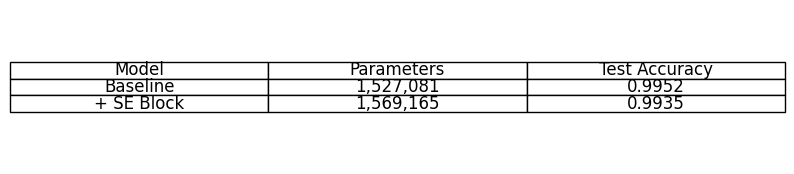

Table saved to /content/drive/MyDrive/cv_project_v2/saved_models/arch_comparison.png


In [22]:
print("\n" + "="*60)
print("ARCHITECTURAL UPGRADE COMPARISON")
print("="*60)
print(f"{'Model':<30} {'Params':>15} {'Test Acc':>12}")
print("-"*60)
print(f"{'MobileNetV3-Small (baseline)':<30} {baseline_params:>15,} {baseline_acc:>12.4f}")
print(f"{'MobileNetV3-Small + SE Block':<30} {se_params:>15,} {se_acc:>12.4f}")
print("="*60)

# Save table as image
fig, ax = plt.subplots(figsize=(10, 2))
ax.axis('tight')
ax.axis('off')
table_data = [
    ["Model", "Parameters", "Test Accuracy"],
    ["Baseline", f"{baseline_params:,}", f"{baseline_acc:.4f}"],
    ["+ SE Block", f"{se_params:,}", f"{se_acc:.4f}"]
]
table = ax.table(cellText=table_data, loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(12)
arch_path = os.path.join(SAVE_DIR, "arch_comparison.png")
plt.savefig(arch_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Table saved to {arch_path}")

## Step 8.2 Grad‑CAM

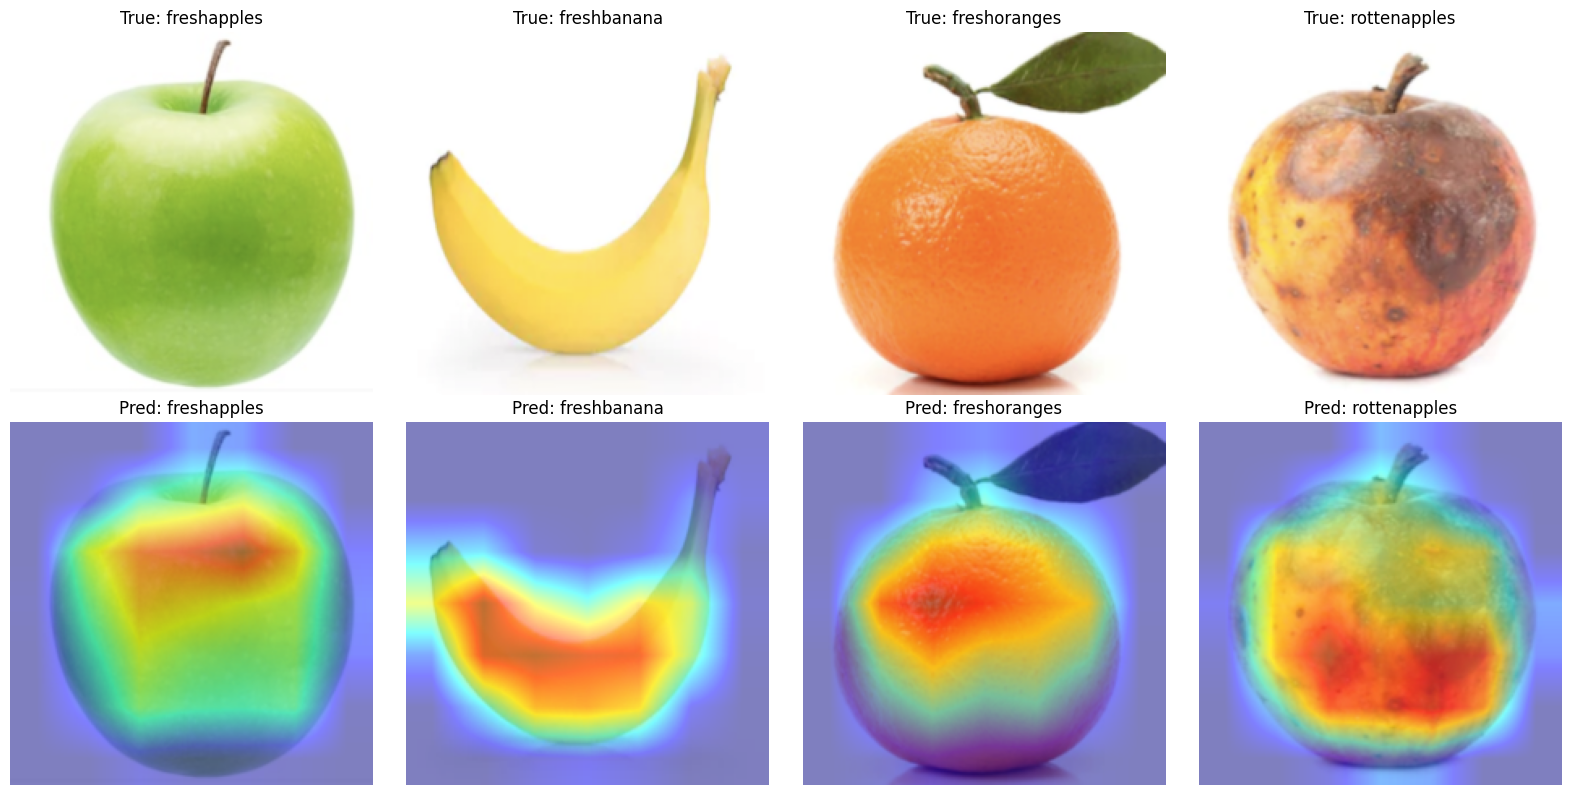

Grad-CAM (original + overlay) saved to /content/drive/MyDrive/cv_project_v2/saved_models/gradcam_original_overlay.png


In [26]:
# Grad-CAM on SE model
# last conv layer before SE
target_layers = [se_model.features[-1][0]]
cam = GradCAM(model=se_model, target_layers=target_layers)


selected_items = []

for class_idx in range(NUM_CLASSES):
    found = False
    for images, labels in test_loader:
        mask = (labels == class_idx)
        if mask.any():
            idx = mask.nonzero()[0].item()
            selected_items.append((images[idx], labels[idx].item()))
            found = True
            break
    if not found:
        print(f"Warning: No image found for class {class_names[class_idx]}")


selected_items = selected_items[:4]

# Prepare figure: 2 rows
n = len(selected_items)
fig, axes = plt.subplots(2, n, figsize=(4*n, 8))

for i, (img_tensor, true_idx) in enumerate(selected_items):
    img_tensor = img_tensor.unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        logits = se_model(img_tensor)
        pred_idx = logits.argmax(dim=1).item()

    # Grad-CAM heatmap
    grayscale_cam = cam(input_tensor=img_tensor, targets=None)[0]

    # Reconstruct original image
    orig_img = inv_normalize(img_tensor[0].cpu())
    orig_img = torch.clamp(orig_img, 0, 1)
    orig_img_np = orig_img.permute(1,2,0).numpy()

    # Overlay
    overlay = show_cam_on_image(orig_img_np, grayscale_cam, use_rgb=True)

    # Top row original
    axes[0, i].imshow(orig_img_np)
    axes[0, i].set_title(f"True: {class_names[true_idx]}")
    axes[0, i].axis('off')

    # Bottom row overlay
    axes[1, i].imshow(overlay)
    axes[1, i].set_title(f"Pred: {class_names[pred_idx]}")
    axes[1, i].axis('off')

plt.tight_layout()
gradcam_path = os.path.join(SAVE_DIR, "gradcam_original_overlay.png")
plt.savefig(gradcam_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Grad-CAM (original + overlay) saved to {gradcam_path}")